# PaceForge — Component 1: Extended Model Benchmark

**Purpose.** This is a supplementary benchmark. The report commits to 4 models
(notebook 02: linear regression, random forest, gradient boosting, neural network). The
literature review also discusses **k-nearest neighbours (KNN)** and **XGBoost**. This
notebook tests both under **identical conditions** to answer the question
"why not KNN or XGBoost?".

This notebook does **not** replace the app model. No model is saved here; the app keeps
`../models/model.joblib` from notebook 02.

**Identical conditions:**

- Same data: `../dataset/clean.csv` (train) and `../dataset/clean_test.csv` (test).
- Same 11 inputs and the same preprocessing, from `build_pipeline` in `src/pipeline.py`
  (including the optional PB with the missing-indicator method).
- Same tuning setup: `RandomizedSearchCV` on the train set only,
  `KFold(5, shuffle=True, random_state=42)`, scoring = negative MAE.
- Same `evaluate()` metrics (MAE, RMSE, MAPE, R²), copied unchanged from notebook 02.

As in notebook 02, the dataset is synthetic, so all scores describe performance **on
this dataset only**.

In [1]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"  # silences the Windows loky "physical cores" warning

import sys
import time

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error,
                             r2_score, root_mean_squared_error)
from sklearn.model_selection import KFold, RandomizedSearchCV
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor

sys.path.insert(0, "..")
from src.pipeline import PB, build_pipeline, feature_list

RANDOM_STATE = 42

# Chart colours (blue = notebook-02 models, orange = extended models, grey = baselines)
BLUE = "#2a78d6"
ORANGE = "#eb6834"
GREY = "#898781"
INK = "#0b0b0b"
GRID = "#e1e0d9"
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
})

## Step 1 — Load the data

Same files, same row counts and same 11 inputs as notebook 02.

In [2]:
train = pd.read_csv("../dataset/clean.csv")
test = pd.read_csv("../dataset/clean_test.csv")

assert len(train) == 77_577
assert len(test) == 19_380

TARGET = "actual_finish_time_minutes"
FEATURES = feature_list()
assert len(FEATURES) == 11

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("Inputs:", FEATURES)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Inputs: ['age', 'bmi', 'weekly_km', 'runs_per_week', 'long_run_distance_km', 'resting_heart_rate_bpm', 'running_experience_months', 'personal_best_minutes', 'gender', 'course_difficulty', 'injury_severity']
Train: (77577, 11) | Test: (19380, 11)


## Step 2 — Tune KNN and XGBoost

Both models are tuned on the **train set only**, exactly as in notebook 02.

| Model | Class | n_iter | Search space |
|---|---|---|---|
| KNN | `KNeighborsRegressor(n_jobs=-1)` | 20 | n_neighbors [5, 15, 25, 50, 100]; weights ["uniform", "distance"]; p [1, 2] |
| XGBoost | `XGBRegressor(tree_method="hist", random_state=42, n_jobs=-1)` | 20 | n_estimators [200, 400, 800]; learning_rate [0.03, 0.05, 0.1]; max_depth [3, 4, 6]; min_child_weight [1, 5, 10]; subsample [0.8, 1.0]; colsample_bytree [0.8, 1.0] |

The KNN search space has exactly 5 × 2 × 2 = 20 combinations, so `n_iter=20` tries all
of them (an exhaustive search). KNN is slow to predict on 77,000 rows, so this step can
take 10–20 minutes. For KNN, `p=1` is Manhattan distance and `p=2` is Euclidean distance.

KNN measures distances between runners, so it depends on all inputs being on the same
scale. The `StandardScaler` inside `build_pipeline` takes care of that.

The best settings are saved to `results/best_params_extended.csv`.

In [3]:
SEARCHES = {
    "KNN": (
        KNeighborsRegressor(n_jobs=-1),
        {
            "model__n_neighbors": [5, 15, 25, 50, 100],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2],
        },
        20,
    ),
    "XGBoost": (
        XGBRegressor(tree_method="hist", random_state=RANDOM_STATE, n_jobs=-1),
        {
            "model__n_estimators": [200, 400, 800],
            "model__learning_rate": [0.03, 0.05, 0.1],
            "model__max_depth": [3, 4, 6],
            "model__min_child_weight": [1, 5, 10],
            "model__subsample": [0.8, 1.0],
            "model__colsample_bytree": [0.8, 1.0],
        },
        20,
    ),
}

tuned = {}
param_rows = []
for name, (model, space, n_iter) in SEARCHES.items():
    start = time.time()
    search = RandomizedSearchCV(
        build_pipeline(model),
        space,
        n_iter=n_iter,
        cv=cv,
        scoring="neg_mean_absolute_error",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    search.fit(X_train, y_train)
    tuned[name] = search.best_estimator_

    best = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    param_rows.append({"Model": name, "Best params": str(best),
                       "CV MAE": round(-search.best_score_, 2)})
    print(f"{name}: CV MAE = {-search.best_score_:.2f} | {best} "
          f"| {time.time() - start:.0f} s")

best_params = pd.DataFrame(param_rows)
best_params.to_csv("../results/best_params_extended.csv", index=False)
best_params

KNN: CV MAE = 12.39 | {'weights': 'distance', 'p': 2, 'n_neighbors': 25} | 388 s


XGBoost: CV MAE = 11.11 | {'subsample': 0.8, 'n_estimators': 800, 'min_child_weight': 10, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 1.0} | 72 s


,Model,Best params,CV MAE
0,KNN,"{'weights': 'distance', 'p': 2, 'n_neighbors':...",12.39
1,XGBoost,"{'subsample': 0.8, 'n_estimators': 800, 'min_c...",11.11


## Step 3 — Evaluate on the test set

The two tuned models are scored on the full test set and on the two groups (has-PB /
first-timer). Their rows are appended to the notebook-02 tables, which are loaded from
`results/`, so all 6 models and both baselines sit in one table:

- `results/table1_extended.csv` — full test set
- `results/table2_extended.csv` — by group

In [4]:
def evaluate(y_true, y_pred):
    return {
        "MAE": round(mean_absolute_error(y_true, y_pred), 1),
        "RMSE": round(root_mean_squared_error(y_true, y_pred), 1),
        "MAPE (%)": round(mean_absolute_percentage_error(y_true, y_pred) * 100, 1),
        "R2": round(r2_score(y_true, y_pred), 3),
    }


# Table 1: full test set
table1 = pd.read_csv("../results/table1_test_overall.csv")
new_rows = pd.DataFrame([{"Model": name, **evaluate(y_test, pipeline.predict(X_test))}
                         for name, pipeline in tuned.items()])

table1_extended = pd.concat([table1, new_rows], ignore_index=True)
table1_extended.to_csv("../results/table1_extended.csv", index=False)
table1_extended

,Model,MAE,RMSE,MAPE (%),R2
0,Linear regression,12.4,16.2,4.4,0.770
1,Random forest,11.3,14.4,4.0,0.816
2,Gradient boosting,11.1,14.2,3.9,0.822
3,Neural network,11.5,14.7,4.0,0.811
4,Mean predictor,27.4,33.7,9.9,-0.000
5,KNN,12.3,15.8,4.4,0.781
6,XGBoost,11.1,14.2,3.9,0.823


In [5]:
# Table 2: by group within the test set
has_pb = test[PB].notna()
groups = {"Has PB": has_pb, "First-timer": ~has_pb}
print("Has PB:", has_pb.sum(), "runners | First-timer:", (~has_pb).sum(), "runners")
assert has_pb.sum() == 16_809
assert (~has_pb).sum() == 2_571

# keep_default_na=False keeps the Riegel row's "N/A" text as text (pandas would read it as NaN)
table2 = pd.read_csv("../results/table2_test_by_group.csv", keep_default_na=False)

parts = []
for group, mask in groups.items():
    new_rows = pd.DataFrame([
        {"Group": group, "n": mask.sum(), "Model": name,
         **evaluate(y_test[mask], pipeline.predict(X_test[mask]))}
        for name, pipeline in tuned.items()
    ])
    parts.append(table2[table2["Group"] == group])
    parts.append(new_rows)

table2_extended = pd.concat(parts, ignore_index=True)
table2_extended.to_csv("../results/table2_extended.csv", index=False)
table2_extended

Has PB: 16809 runners | First-timer: 2571 runners


,Group,n,Model,MAE,RMSE,MAPE (%),R2
0,Has PB,16809,Linear regression,11.1,14.0,3.9,0.828
1,Has PB,16809,Random forest,10.5,13.2,3.7,0.846
2,Has PB,16809,Gradient boosting,10.3,13.0,3.6,0.851
3,Has PB,16809,Neural network,10.6,13.3,3.7,0.844
4,Has PB,16809,Riegel baseline,29.6,33.9,10.2,-0.019
5,Has PB,16809,KNN,11.4,14.3,4.0,0.819
6,Has PB,16809,XGBoost,10.3,12.9,3.6,0.852
7,First-timer,2571,Linear regression,21.1,26.4,7.6,0.403
8,First-timer,2571,Random forest,16.7,20.9,5.9,0.627
9,First-timer,2571,Gradient boosting,16.3,20.5,5.8,0.64


## Step 4 — XGBoost vs gradient boosting

**Decision rule (set before looking at the results):** if XGBoost's test MAE is within
**0.5 minutes** of gradient boosting's, the two are treated as a **tie**. In a tie the app
keeps the notebook-02 model, because it needs only scikit-learn, which is one dependency
fewer than adding the `xgboost` package.

The MAE values compared here are the ones in Table 1 (rounded to 1 decimal).

In [6]:
mae = table1_extended.set_index("Model")["MAE"]
difference = mae["XGBoost"] - mae["Gradient boosting"]

print(f"Gradient boosting MAE: {mae['Gradient boosting']:.1f} min")
print(f"XGBoost MAE:           {mae['XGBoost']:.1f} min")
print(f"Difference (XGBoost - gradient boosting): {difference:+.1f} min")

if abs(difference) <= 0.5:
    print("Verdict: TIE (within 0.5 min). The app keeps the notebook-02 model.")
elif difference < 0:
    print("Verdict: XGBoost is better by more than 0.5 min.")
else:
    print("Verdict: gradient boosting is better by more than 0.5 min.")

Gradient boosting MAE: 11.1 min
XGBoost MAE:           11.1 min
Difference (XGBoost - gradient boosting): +0.0 min
Verdict: TIE (within 0.5 min). The app keeps the notebook-02 model.


## Step 5 — MAE comparison chart

Test MAE for all 6 models and both baselines. Blue = the 4 models from notebook 02,
orange = the 2 extended models from this notebook, grey = baselines.

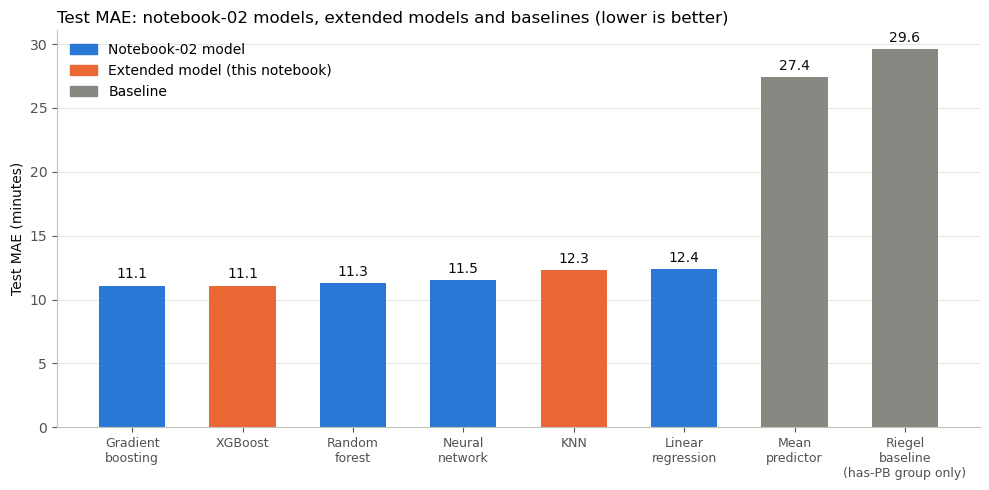

In [7]:
riegel_mae = float(table2.loc[(table2["Group"] == "Has PB") & (table2["Model"] == "Riegel baseline"), "MAE"].iloc[0])

mae_chart = pd.DataFrame({
    "Model": list(table1_extended["Model"]) + ["Riegel baseline\n(has-PB group only)"],
    "MAE": list(table1_extended["MAE"]) + [riegel_mae],
})

def bar_colour(model):
    if model.startswith(("Mean", "Riegel")):
        return GREY
    if model in tuned:
        return ORANGE
    return BLUE

mae_chart["Colour"] = mae_chart["Model"].map(bar_colour)
mae_chart["Label"] = mae_chart["Model"].str.replace(" ", "\n", n=1)  # two-line labels so they don't overlap
mae_chart = mae_chart.sort_values("MAE")

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(mae_chart["Label"], mae_chart["MAE"], color=mae_chart["Colour"], width=0.6)
ax.bar_label(bars, fmt="%.1f", padding=3, color=INK)
ax.set_ylabel("Test MAE (minutes)")
ax.set_title("Test MAE: notebook-02 models, extended models and baselines (lower is better)", loc="left")
ax.grid(axis="x", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in (BLUE, ORANGE, GREY)],
          labels=["Notebook-02 model", "Extended model (this notebook)", "Baseline"],
          frameon=False, loc="upper left")
plt.setp(ax.get_xticklabels(), fontsize=9)
fig.tight_layout()
fig.savefig("../figures/mae_comparison_extended.png", dpi=300)
plt.show()

Note: the Riegel bar is scored on the has-PB group only (16,809 runners), because
Riegel cannot be applied to first-timers. All other bars are scored on the full test
set (19,380 runners).

## Step 6 — Models from the literature review that are not tested

- **LSTM / GRU.** These are sequence models: they learn from a *series* of runs per
  runner (for example, weeks of training logs). This dataset has **one row per runner**,
  so there is no sequence to learn from.
- **Kernel SVR.** Training time grows very quickly with the number of rows. The
  scikit-learn documentation for `SVR` notes that its fit time is more than quadratic in
  the number of samples, which makes it hard to scale beyond a few tens of thousands of
  rows. With 77,577 training rows, and 5-fold CV on top, it is impractical here.
- **DDPG-LSTM, reinforcement learning, genetic algorithms, case-based reasoning (CBR) and
  fuzzy logic.** These are methods for **generating or adapting training plans**, not for
  predicting race times, so they do not belong in a race-time benchmark. (In PaceForge,
  fuzzy logic is used for plan generation in Component 2; DDPG-LSTM reinforcement
  learning was scoped out of the project.)